# ResNet-56 na CIFAR-10

In [1]:
!nvidia-smi

Mon Nov 23 21:48:49 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import time, json, random
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.transforms as T
import matplotlib.pyplot as plt

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device, torch.cuda.get_device_name(0) if device == 'cuda' else '')
torch.backends.cudnn.benchmark = True

CFG = dict(
    n=9,
    batch_size=128,
    lr=0.1,
    momentum=0.9,
    weight_decay=1e-4,
    milestones=[32000, 48000],
    total_iters=64000,
    use_amp=True,
    seed=0,
)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(CFG['seed'])

device: cuda Tesla T4


In [4]:

MEAN = (0.4914, 0.4822, 0.4465)
STD  = (0.2470, 0.2435, 0.2616)

train_tf = T.Compose([
    T.RandomCrop(32, padding=4),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])
test_tf = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])

train_set = torchvision.datasets.CIFAR10('./data', train=True,  download=True, transform=train_tf)
test_set  = torchvision.datasets.CIFAR10('./data', train=False, download=True, transform=test_tf)

train_loader = torch.utils.data.DataLoader(train_set, batch_size=CFG['batch_size'], shuffle=True,
                                           num_workers=2, pin_memory=True, persistent_workers=True)
test_loader  = torch.utils.data.DataLoader(test_set, batch_size=500, shuffle=False,
                                           num_workers=2, pin_memory=True, persistent_workers=True)

print(len(train_set), len(test_set), 'iteracji na epokę:', len(train_loader))

50000 10000 iteracji na epokę: 391


In [9]:
class Block(nn.Module):
    def __init__(self, in_c, out_c, stride, residual=True):
        super().__init__()
        self.conv1 = nn.Conv2d(in_c, out_c, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_c)
        self.conv2 = nn.Conv2d(out_c, out_c, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_c)
        self.stride, self.pad, self.residual = stride, out_c - in_c, residual

    def shortcut(self, x):
        if self.stride == 1 and self.pad == 0:
            return x
        x = x[:, :, ::self.stride, ::self.stride]
        return F.pad(x, (0, 0, 0, 0, 0, self.pad))

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:
            out = out + self.shortcut(x)
        return F.relu(out)

class CifarResNet(nn.Module):
    def __init__(self, n=9, num_classes=10, residual=True):
        super().__init__()
        self.conv = nn.Conv2d(3, 16, 3, 1, 1, bias=False)
        self.bn = nn.BatchNorm2d(16)
        blocks, in_c = [], 16
        for out_c, stride in [(16, 1), (32, 2), (64, 2)]:
            for i in range(n):
                blocks.append(Block(in_c, out_c, stride if i == 0 else 1, residual))
                in_c = out_c
        self.blocks = nn.Sequential(*blocks)
        self.fc = nn.Linear(64, num_classes)
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')

    def forward(self, x):
        x = F.relu(self.bn(self.conv(x)))
        x = self.blocks(x)
        x = F.adaptive_avg_pool2d(x, 1).flatten(1)
        return self.fc(x)

m = CifarResNet(n=CFG['n'])
n_params = sum(p.numel() for p in m.parameters())
n_layers = 1 + 6 * CFG['n'] + 1
print(f'warstwy z wagami: {n_layers}, parametry: {n_params/1e6:.2f}M')
del m

warstwy z wagami: 56, parametry: 0.85M


In [6]:
def evaluate(model, loader):
    model.eval()
    wrong, total, loss_sum = 0, 0, 0.0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=CFG['use_amp'] and device == 'cuda'):
                out = model(x)
            loss_sum += F.cross_entropy(out.float(), y, reduction='sum').item()
            wrong += (out.argmax(1) != y).sum().item()
            total += y.numel()
    return 100.0 * wrong / total, loss_sum / total


def train(residual=True, name='resnet56'):
    set_seed(CFG['seed'])
    model = CifarResNet(n=CFG['n'], residual=residual).to(device).to(memory_format=torch.channels_last)
    opt = torch.optim.SGD(model.parameters(), lr=CFG['lr'], momentum=CFG['momentum'],
                          weight_decay=CFG['weight_decay'])
    sched = torch.optim.lr_scheduler.MultiStepLR(opt, milestones=CFG['milestones'], gamma=0.1)
    use_amp = CFG['use_amp'] and device == 'cuda'
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

    hist = dict(epoch=[], iter=[], train_err=[], test_err=[], train_loss=[], test_loss=[])
    it, epoch, t0 = 0, 0, time.time()
    while it < CFG['total_iters']:
        model.train()
        wrong, total, loss_sum = 0, 0, 0.0
        for x, y in train_loader:
            x = x.to(device, non_blocking=True).to(memory_format=torch.channels_last)
            y = y.to(device, non_blocking=True)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
                out = model(x)
                loss = F.cross_entropy(out, y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            it += 1

            wrong += (out.argmax(1) != y).sum().item()
            total += y.numel()
            loss_sum += loss.item() * y.numel()
            if it >= CFG['total_iters']:
                break

        epoch += 1
        te, tl = evaluate(model, test_loader)
        hist['epoch'].append(epoch); hist['iter'].append(it)
        hist['train_err'].append(100.0 * wrong / total); hist['train_loss'].append(loss_sum / total)
        hist['test_err'].append(te); hist['test_loss'].append(tl)
        print(f'[{name}] ep {epoch:3d} | it {it:5d} | lr {opt.param_groups[0]["lr"]:.4f} | '
              f'train err {hist["train_err"][-1]:5.2f}% | test err {te:5.2f}% | {time.time()-t0:6.0f}s')

    torch.save(model.state_dict(), f'{name}.pt')
    json.dump(hist, open(f'{name}_hist.json', 'w'))
    return model, hist

## Trening ResNet-56

In [ ]:
model_res, hist_res = train(residual=True, name='resnet56')
print('Końcowy błąd testowy ResNet-56: %.2f%%' % hist_res['test_err'][-1])

/tmp/ipykernel_1205/61596494.py:39: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


[resnet56] ep   1 | it   391 | lr 0.1000 | train err 80.74% | test err 76.36% |     29s
[resnet56] ep   2 | it   782 | lr 0.1000 | train err 70.34% | test err 62.42% |     58s
[resnet56] ep   3 | it  1173 | lr 0.1000 | train err 57.06% | test err 52.55% |     87s
[resnet56] ep   4 | it  1564 | lr 0.1000 | train err 47.01% | test err 43.21% |    116s
[resnet56] ep   5 | it  1955 | lr 0.1000 | train err 39.87% | test err 37.26% |    144s
[resnet56] ep   6 | it  2346 | lr 0.1000 | train err 33.33% | test err 31.89% |    172s
[resnet56] ep   7 | it  2737 | lr 0.1000 | train err 28.23% | test err 29.10% |    200s
[resnet56] ep   8 | it  3128 | lr 0.1000 | train err 24.77% | test err 27.52% |    228s
[resnet56] ep   9 | it  3519 | lr 0.1000 | train err 22.37% | test err 22.64% |    257s
[resnet56] ep  10 | it  3910 | lr 0.1000 | train err 20.45% | test err 22.52% |    285s
[resnet56] ep  11 | it  4301 | lr 0.1000 | train err 18.97% | test err 20.64% |    314s
[resnet56] ep  12 | it  4692 | l

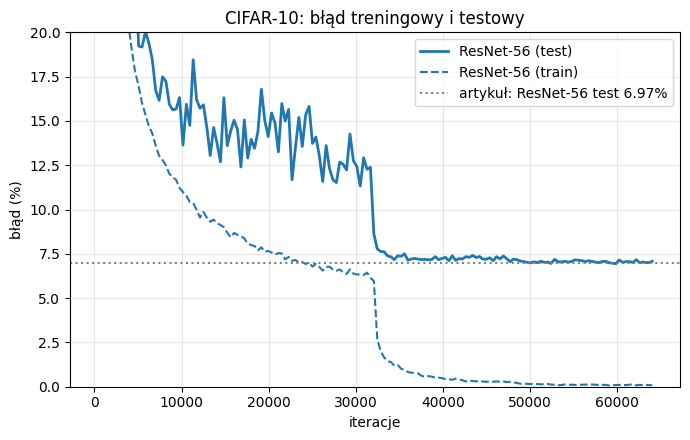

In [ ]:
def plot(hists, title):
    plt.figure(figsize=(7, 4.5))
    for name, h in hists.items():
        l, = plt.plot(h['iter'], h['test_err'], lw=2, label=f'{name} (test)')
        plt.plot(h['iter'], h['train_err'], '--', color=l.get_color(), label=f'{name} (train)')
    plt.axhline(6.97, color='gray', ls=':', label='artykuł: ResNet-56 test 6.97%')
    plt.ylim(0, 20); plt.xlabel('iteracje'); plt.ylabel('błąd (%)')
    plt.title(title); plt.grid(alpha=0.3); plt.legend()
    plt.tight_layout(); plt.savefig('curves.png', dpi=150); plt.show()

hists = {'ResNet-56': hist_res}
try:
    hists['plain-56'] = hist_plain
except NameError:
    pass
plot(hists, 'CIFAR-10: błąd treningowy i testowy')

# Trening ResNet-20

In [7]:
CFG['n'] = 3
model_r20, hist_r20 = train(residual=True, name='resnet20')
CFG['n'] = 9

[resnet20] ep   1 | it   391 | lr 0.1000 | train err 56.40% | test err 46.18% |     31s
[resnet20] ep   2 | it   782 | lr 0.1000 | train err 36.80% | test err 35.17% |     54s
[resnet20] ep   3 | it  1173 | lr 0.1000 | train err 29.06% | test err 32.49% |     76s
[resnet20] ep   4 | it  1564 | lr 0.1000 | train err 24.63% | test err 27.19% |     99s
[resnet20] ep   5 | it  1955 | lr 0.1000 | train err 22.39% | test err 24.17% |    121s
[resnet20] ep   6 | it  2346 | lr 0.1000 | train err 20.44% | test err 23.80% |    143s
[resnet20] ep   7 | it  2737 | lr 0.1000 | train err 19.31% | test err 27.48% |    166s
[resnet20] ep   8 | it  3128 | lr 0.1000 | train err 18.03% | test err 21.73% |    187s
[resnet20] ep   9 | it  3519 | lr 0.1000 | train err 17.40% | test err 20.04% |    210s
[resnet20] ep  10 | it  3910 | lr 0.1000 | train err 16.44% | test err 22.50% |    232s
[resnet20] ep  11 | it  4301 | lr 0.1000 | train err 15.85% | test err 20.44% |    254s
[resnet20] ep  12 | it  4692 | l

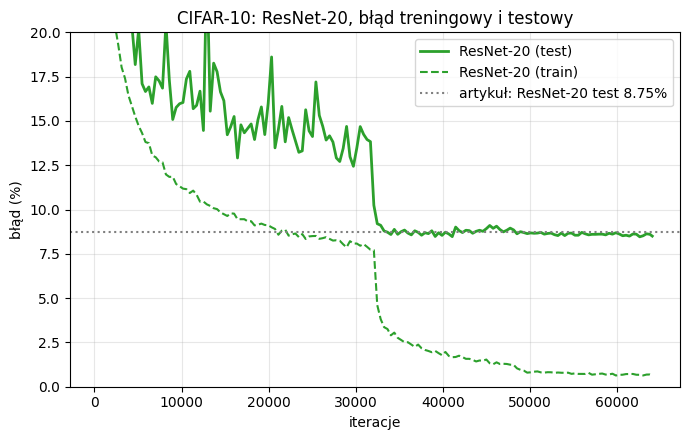

In [8]:
def plot_r20(h, title='CIFAR-10: ResNet-20, błąd treningowy i testowy'):
    plt.figure(figsize=(7, 4.5))
    color = 'tab:green'
    plt.plot(h['iter'], h['test_err'], lw=2, color=color, label='ResNet-20 (test)')
    plt.plot(h['iter'], h['train_err'], '--', color=color, label='ResNet-20 (train)')
    plt.axhline(8.75, color='gray', ls=':', label='artykuł: ResNet-20 test 8.75%')
    plt.ylim(0, 20); plt.xlabel('iteracje'); plt.ylabel('błąd (%)')
    plt.title(title); plt.grid(alpha=0.3); plt.legend()
    plt.tight_layout(); plt.savefig('curves_resnet20.png', dpi=150); plt.show()

plot_r20(hist_r20)